In [11]:
import pandas as pd 
import numpy as np  

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#import torch
#import torch.nn as nn
#from torch.utils.data import TensorDataset, DataLoader

#path = r"C:\Users\danhm\OneDrive\Desktop\Electivo_NN\Proyecto_1\150k.csv" # obs: manualmente se quito la primera fila para poder trabajar con un formato mas simple 
path = '150k.csv'
df = pd.read_csv( path )
print(df.shape) 

(150000, 68)


In [ ]:
# cuantos -9999 hay por columna (y el %), yo se que los nan son -9999
def resumen_sentinel(df, sentinel=-9999):
    counts = (df == sentinel).sum(numeric_only=False)
    perc = counts / len(df.columns)
    rep = pd.DataFrame({"count": counts, "percent": perc}).sort_values("count", ascending=False)
    return rep

print(resumen_sentinel(df))

               count  percent
deVRadErr_g       15   0.0001
deVRad_g          15   0.0001
dered_u           15   0.0001
dered_g           15   0.0001
psfMagErr_g       15   0.0001
...              ...      ...
petroRad_r         0   0.0000
modelMagErr_r      0   0.0000
psfMagErr_i        0   0.0000
psfMagErr_r        0   0.0000
ra                 0   0.0000

[68 rows x 2 columns]


Es extraño, arriba me indica que hay 15 filas con estos valores nan, pero luego de quitarlas te quedan 149983, eso significa que quitaste 15 o 17?

In [2]:
filas_sanas = (df != -9999).all(axis=1)
df = df.loc[filas_sanas].reset_index(drop=True)
print(f"filas tras filtrar -9999: {len(df)}")

filas tras filtrar -9999: 149983


In [6]:
print(df.columns) # Todas las columnas

Index(['z', 'zErr', 'dec', 'decErr', 'dered_g', 'dered_i', 'dered_r',
       'dered_u', 'dered_z', 'deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z',
       'deVRadErr_g', 'deVRadErr_i', 'deVRadErr_r', 'deVRadErr_z', 'expPhi_g',
       'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z', 'expRad_g', 'expRad_i',
       'expRad_r', 'expRad_z', 'expRadErr_g', 'expRadErr_i', 'expRadErr_r',
       'expRadErr_z', 'extinction_g', 'extinction_i', 'extinction_r',
       'extinction_u', 'extinction_z', 'fiberMag_g', 'fiberMag_i',
       'fiberMag_r', 'fiberMag_u', 'fiberMag_z', 'fiberMagErr_g',
       'fiberMagErr_i', 'fiberMagErr_r', 'fiberMagErr_u', 'fiberMagErr_z',
       'modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z',
       'modelMagErr_g', 'modelMagErr_i', 'modelMagErr_r', 'modelMagErr_u',
       'modelMagErr_z', 'petroRad_r', 'petroRadErr_r', 'psfMag_g', 'psfMag_i',
       'psfMag_r', 'psfMag_u', 'psfMag_z', 'psfMagErr_g', 'psfMagErr_i',
       'psfMagErr_r', 'psfMagErr_u', 

In [3]:
error_cols = [col for col in df.columns if "err" in col.lower()] # separa las columnas que guardan los errores
print(len(error_cols))      # lista de columnas de errores

datos_sin_errores = df.drop(columns=error_cols)
datos_errores     = df[error_cols]

print('sin errores: ',len(datos_sin_errores.columns),' errores: ',len(datos_errores.columns))

26
sin errores:  42  errores:  26


In [5]:
# Solo columnas numéricas
corr_matrix = datos_sin_errores.corr(method='pearson').abs()


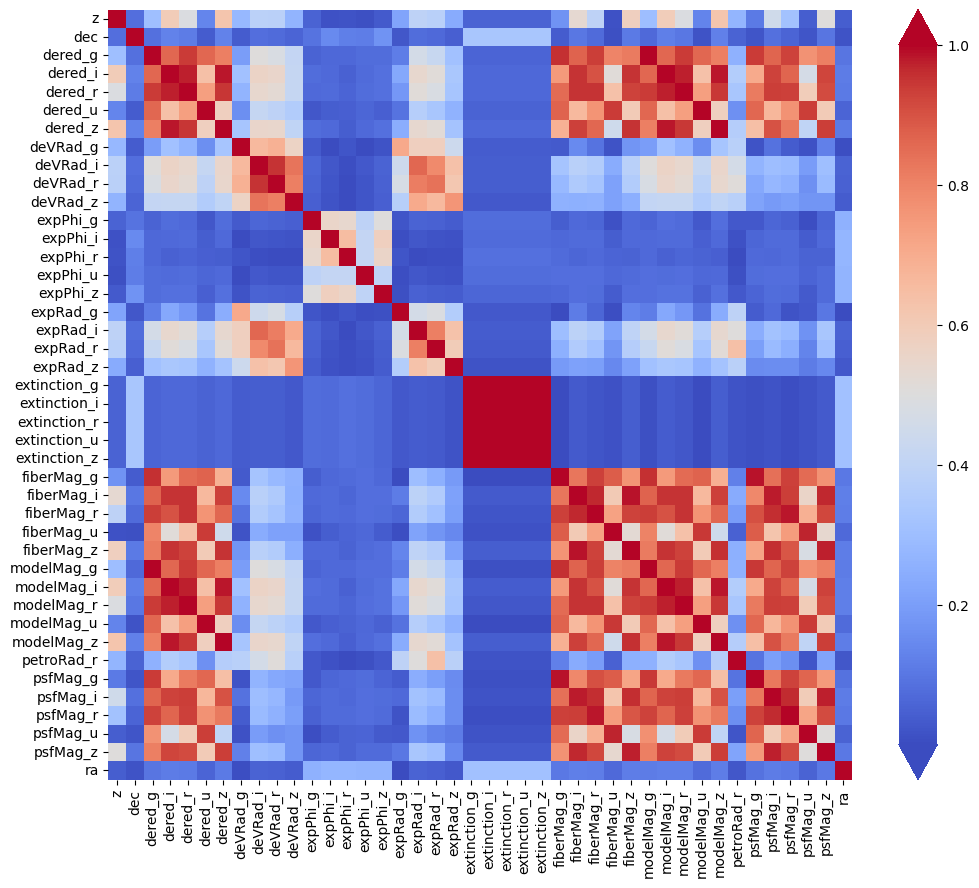

In [13]:
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, cmap="coolwarm", cbar_kws={'extend': 'both',})
plt.show()


In [6]:
umbral = 0.9

upper = corr_matrix.where( np.triu(np.ones(corr_matrix.shape), k=1).astype(bool) ) # se queda solo con la mitad superiror y la diagonal de la matriz, evitapares duplicados

cols_altamente_corr = [col for col in upper.columns if any(upper[col] > umbral)] # correlacion alta
print(len(cols_altamente_corr))


22


In [7]:
datos_sin_corr = datos_sin_errores.drop(columns=cols_altamente_corr) # sin errores y correlacion baja

DF = datos_sin_corr # df final
print(DF.shape)
print(DF.columns)

(149983, 20)
Index(['z', 'dec', 'dered_g', 'dered_i', 'dered_u', 'deVRad_g', 'deVRad_i',
       'deVRad_z', 'expPhi_g', 'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z',
       'expRad_g', 'expRad_i', 'expRad_r', 'expRad_z', 'extinction_g',
       'petroRad_r', 'ra'],
      dtype='object')


In [15]:
# Export this dataframe

DF.to_pickle('data_red_bruta.pkl')

In [187]:
X = DF.drop(columns=[DF.columns[0]])  # resto de variables
Y = DF[DF.columns[0]]                 # columna a predecir


In [188]:
#scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X) # normalizacion de los datos


In [189]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device) # por si se puede usar gpu

cuda


Nota: fijar la semilla en una linea previa (al momento de fijar el resto de parámetros). Esto para asegurar que el resto de procesos random que tienen lugar en las distintas funciones de una cierta librería, sean todos con la misma semilla

In [ ]:
# ==== 6) Split train/test ====
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler() # se escalan los datos 
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)



X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values.reshape(-1, 1), dtype=torch.float32)

X_test_t  = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t  = torch.tensor(y_test.values.reshape(-1, 1), dtype=torch.float32)

batch_size = 512
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test_t,  y_test_t),  batch_size=batch_size, shuffle=False)

In [191]:
# MLP 64-32-16-8 con Tanh 
class MLP(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 16),
            nn.Tanh(),
            nn.Linear(16, 8),
            nn.Tanh(),
            nn.Linear(8, 1)   
        )
    def forward(self, x):
        return self.net(x)

model = MLP(in_dim=X_train_t.shape[1]).to(device)

In [192]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [193]:
# Train
epochs = 150
model.train()
for epoch in range(1, epochs+1):
    running_loss = 0.0
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    # evaluacion en validacion
    model.eval()
    with torch.no_grad():
        preds = []
        gts = []
        for xb, yb in test_loader:
            xb = xb.to(device)
            pred = model(xb)
            preds.append(pred.cpu().numpy())
            gts.append(yb.numpy())
        y_pred_val = np.vstack(preds).ravel()
        y_true_val = np.vstack(gts).ravel()
        val_mse = mean_squared_error(y_true_val, y_pred_val)
    model.train()

    if epoch % 50 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Train MSE: {epoch_loss:.6f} | Val MSE: {val_mse:.6f}")

# metricas
model.eval()
with torch.no_grad():
    y_pred_test = model(X_test_t.to(device)).cpu().numpy().ravel()

mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
r2  = r2_score(y_test, y_pred_test)

print(f"\nResultados en Test:")
print(f"  MSE: {mse:.6f}")
print(f"  MAE: {mae:.6f}")
print(f"  R2 : {r2:.6f}")

Epoch   1 | Train MSE: 0.222143 | Val MSE: 0.166078
Epoch  50 | Train MSE: 0.078773 | Val MSE: 0.085239
Epoch 100 | Train MSE: 0.071738 | Val MSE: 0.085993
Epoch 150 | Train MSE: 0.066017 | Val MSE: 0.087144

Resultados en Test:
  MSE: 0.087144
  MAE: 0.126499
  R2 : 0.814030
